In [1]:
import pathlib

print("Current working directory:", pathlib.Path().resolve())

Current working directory: /Users/lms/Documents/Forschung/textClust_hpo


# Comparison among algorithms

In [2]:
import pandas as pd
import os
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from moocore import hypervolume

from smac_hpo.evaluation.utils import build_results_csv, store_results_csv, load_results_csv, normalize, pareto_optimal_points 
from smac_hpo.evaluation.utils import COLORS, COLOR_PALETTE, ALGORITHM_ORDER, OLD_DATASETS, NEW_DATASETS, ALL_DATASETS, NUM_SEEDS, NUM_REPS
from smac_hpo.evaluation.utils import SINGLE_COLUMN_WIDTH, PANEL_HEIGHT, facet_aspect, set_publication_style
set_publication_style()

FIGURES_DIR = pathlib.Path("figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

np.random.seed(42)

In [3]:
full_opt_results_df = load_results_csv()
assert full_opt_results_df["dataset"].isin(ALL_DATASETS).all(), "Error: Some datasets in the results are not in the list of known datasets. Please check the dataset names."
assert full_opt_results_df["dataset"].isin(OLD_DATASETS).any(), "Error: No old datasets found in the results. Please check the dataset names."
assert full_opt_results_df["dataset"].isin(NEW_DATASETS).any(), "Error: No new datasets found in the results. Please check the dataset names."

for _, group in full_opt_results_df.groupby(["dataset"]):
    full_opt_results_df.loc[group.index, ["avg_throughput_normalized", "adj_mutual_info_final_normalized"]] = normalize(group, columns=["avg_throughput", "adj_mutual_info_final"], use_log=[True, False])[["avg_throughput", "adj_mutual_info_final"]].values


cv_results_df = full_opt_results_df[(full_opt_results_df["config_source"] == "cv") & full_opt_results_df["dataset"].isin(NEW_DATASETS)].copy()
default_results_df = full_opt_results_df[(full_opt_results_df["config_source"] == "default") & full_opt_results_df["dataset"].isin(NEW_DATASETS)].copy()
assert len(full_opt_results_df) != 0, "Error: No full optimization results found. Please run the full optimization first."

In [4]:
results_ami = []
results_throughput = []

for n_seeds in NUM_SEEDS:
    for i in range(NUM_REPS):
        seeds = np.random.choice(cv_results_df["seed"].unique(), size=n_seeds, replace=False)
        subgroup = cv_results_df[cv_results_df["seed"].isin(seeds)].copy()
        test_group = subgroup[subgroup["is_test"] == True]
        train_group = subgroup[subgroup["is_test"] == False]
        df_mean_config_performance = (
            train_group.groupby(["config_id", "loo_datasets", "config", "algorithm"])[["adj_mutual_info_final", "avg_throughput_normalized"]]
            .mean()
            .reset_index()
        )
        idx_best_ami_train = (
            df_mean_config_performance
            .groupby(["loo_datasets", "algorithm"])["adj_mutual_info_final"]
            .idxmax()
        )
        idx_best_throughput_train = (
            df_mean_config_performance
            [df_mean_config_performance["adj_mutual_info_final"] > 0.3]
            .groupby(["loo_datasets", "algorithm"])["avg_throughput_normalized"]
            .idxmax()
        )

        best_config_ids_ami_train = df_mean_config_performance.loc[idx_best_ami_train, "config_id"].values
        best_config_ids_throughput_train = df_mean_config_performance.loc[idx_best_throughput_train, "config_id"].values

        performance_best_configs_ami_on_test = (
            test_group[test_group["config_id"].isin(best_config_ids_ami_train)][["algorithm", "dataset", "adj_mutual_info_final"]]
        )
        performance_best_configs_throughput_on_test = (
            test_group[test_group["config_id"].isin(best_config_ids_throughput_train)][["algorithm", "dataset", "avg_throughput_normalized"]]
        )
        df = performance_best_configs_ami_on_test.copy()
        df["n_seeds"] = n_seeds
        df["n_reps"] = i
        df["seeds"] = str(seeds.tolist())
        results_ami.append(df)  
        
        df = performance_best_configs_throughput_on_test.copy()
        df["n_seeds"] = n_seeds
        df["n_reps"] = i
        df["seeds"] = str(seeds.tolist())
        results_throughput.append(df)     
        
best_ami_df: pd.DataFrame = pd.concat(results_ami, ignore_index=True)
best_throughput_df: pd.DataFrame = pd.concat(results_throughput, ignore_index=True)

display(best_ami_df)
display(best_throughput_df)


,algorithm,dataset,adj_mutual_info_final,n_seeds,n_reps,seeds
0,FSD-SBERT,Arabic_Twitter,0.500234,1,0,[8.0]
1,FSD-SBERT,Semantic40-T,0.741158,1,0,[8.0]
2,embClust,Arabic_Twitter,0.356342,1,0,[8.0]
3,embClust,Semantic40-T,0.688784,1,0,[8.0]
4,textClust,Arabic_Twitter,0.185764,1,0,[8.0]
...,...,...,...,...,...,...
21595,FSD-SBERT,Semantic5-T,0.604594,10,44,"[9.0, 3.0, 1.0, 2.0, 5.0, 4.0, 10.0, 6.0, 7.0,..."
21596,textClust,CrisisLexT7,0.604082,10,44,"[9.0, 3.0, 1.0, 2.0, 5.0, 4.0, 10.0, 6.0, 7.0,..."
21597,textClust,Semantic5-T,0.651386,10,44,"[9.0, 3.0, 1.0, 2.0, 5.0, 4.0, 10.0, 6.0, 7.0,..."
21598,embClust,CrisisLexT7,0.627651,10,44,"[9.0, 3.0, 1.0, 2.0, 5.0, 4.0, 10.0, 6.0, 7.0,..."


,algorithm,dataset,avg_throughput_normalized,n_seeds,n_reps,seeds
0,FSD-SBERT,Arabic_Twitter,0.923528,1,0,[8.0]
1,FSD-SBERT,Semantic40-T,0.899179,1,0,[8.0]
2,textClust,Arabic_Twitter,0.912885,1,0,[8.0]
3,textClust,Semantic40-T,0.920823,1,0,[8.0]
4,embClust,Arabic_Twitter,0.392148,1,0,[8.0]
...,...,...,...,...,...,...
21595,embClust,Semantic5-T,0.856637,10,44,"[9.0, 3.0, 1.0, 2.0, 5.0, 4.0, 10.0, 6.0, 7.0,..."
21596,textClust,CrisisLexT7,0.934483,10,44,"[9.0, 3.0, 1.0, 2.0, 5.0, 4.0, 10.0, 6.0, 7.0,..."
21597,textClust,Semantic5-T,0.935007,10,44,"[9.0, 3.0, 1.0, 2.0, 5.0, 4.0, 10.0, 6.0, 7.0,..."
21598,FSD-SBERT,CrisisLexT7,0.917894,10,44,"[9.0, 3.0, 1.0, 2.0, 5.0, 4.0, 10.0, 6.0, 7.0,..."


In [5]:
df = default_results_df.copy()
df["is_artificial"] = df["dataset"].str.contains("Semantic") | df["dataset"].str.contains("Arabic") | df["dataset"].str.contains("Event2018")

median_default_ami_df = (
    df.copy()
    .groupby(["algorithm", "is_artificial", "config_id"])[["adj_mutual_info_final", "avg_throughput_normalized"]]
    .mean()
    .reset_index()
    .groupby(["algorithm", "is_artificial"])[["adj_mutual_info_final", "avg_throughput_normalized"]]
    .max()
    .reset_index()
)
median_default_ami_df

,algorithm,is_artificial,adj_mutual_info_final,avg_throughput_normalized
0,FSD-SBERT,False,0.460041,0.676190
1,FSD-SBERT,True,0.529270,0.562519
2,embClust,False,0.302468,0.661092
3,embClust,True,0.436662,0.553324
4,textClust,False,0.545603,0.859115
5,textClust,True,0.386806,0.861904


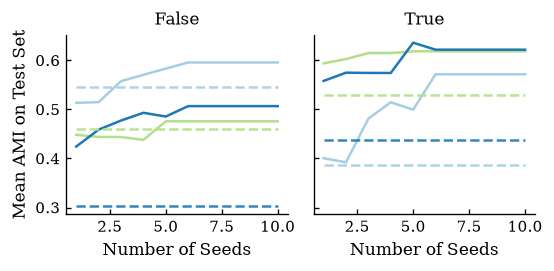

In [6]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

df = best_ami_df.copy()
df["is_artificial"] = df["dataset"].str.contains("Semantic") | df["dataset"].str.contains("Arabic") | df["dataset"].str.contains("Event2018")

def draw_panel(data, **kwargs):
    ax = plt.gca()
    
    df = (
        data.groupby(["dataset", "n_seeds", "algorithm", "is_artificial"])["adj_mutual_info_final"]
        .median()
        .reset_index()
    )
    
    sns.lineplot(data=df, x="n_seeds", hue="algorithm", y="adj_mutual_info_final",
                 palette=COLORS, hue_order=ALGORITHM_ORDER, estimator="mean", errorbar=None, ax=ax)
    ax.set_ylabel("Mean AMI on Test Set")
    ax.set_xlabel("Number of Seeds")
    is_artificial = df["is_artificial"].iloc[0]
    for algorithm, median_ami in median_default_ami_df.loc[median_default_ami_df["is_artificial"] == is_artificial].set_index("algorithm")["adj_mutual_info_final"].items():
        ax.hlines(y=median_ami, xmin=1, xmax=10, color=COLORS[algorithm], linestyle="--", alpha=0.9,)

g = sns.FacetGrid(df, col="is_artificial", sharey=True, height=PANEL_HEIGHT, aspect=facet_aspect(2, PANEL_HEIGHT, SINGLE_COLUMN_WIDTH))
g.map_dataframe(draw_panel)

# Change panel titles 
g.set_titles("{col_name}")

legend_handels = [
    Line2D([0], [0], color=COLORS["FSD-SBERT"], label="FSD-SBERT"),
    Line2D([0], [0], color=COLORS["embClust"], label="embClust"),
    Line2D([0], [0], color=COLORS["textClust"], label="textClust"),
    Line2D([0], [0], color="black", label="Best Default Configuration", linestyle="--")
]

legend_fig = plt.figure()
legend_fig.legend(handles=legend_handels, loc="center", ncol=4)
legend_fig.savefig(
    FIGURES_DIR / "comparison_seed_performance_legend.pdf",
    format="pdf",
    bbox_inches="tight",
    pad_inches=0,
)
plt.close(legend_fig)
g.set_axis_labels("Number of Seeds", "Mean AMI on Test Set")
g.figure.savefig(
    FIGURES_DIR / "comparison_ami_by_seed.pdf",
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.1,
)

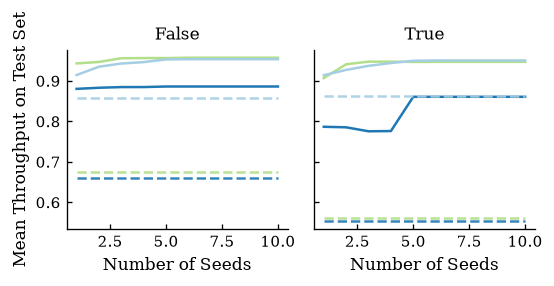

In [7]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

df = best_throughput_df.copy()
df["is_artificial"] = df["dataset"].str.contains("Semantic") | df["dataset"].str.contains("Arabic") | df["dataset"].str.contains("Event2018")

def draw_panel(data, **kwargs):
    ax = plt.gca()
    
    df = (
        data.groupby(["dataset", "n_seeds", "algorithm", "is_artificial"])["avg_throughput_normalized"]
        .median()
        .reset_index()
    )
    
    sns.lineplot(data=df, x="n_seeds", hue="algorithm", y="avg_throughput_normalized",
                 palette=COLORS, hue_order=ALGORITHM_ORDER, estimator="mean", errorbar=None, ax=ax)
    ax.set_ylabel("Mean Normalized Throughput on Test Set")
    ax.set_xlabel("Number of Seeds")
    is_artificial = df["is_artificial"].iloc[0]
    for algorithm, median_throughput in median_default_ami_df.loc[median_default_ami_df["is_artificial"] == is_artificial].set_index("algorithm")["avg_throughput_normalized"].items():
        ax.hlines(y=median_throughput, xmin=1, xmax=10, color=COLORS[algorithm], linestyle="--", alpha=0.9,)

g = sns.FacetGrid(df, col="is_artificial", sharey=True, height=PANEL_HEIGHT, aspect=facet_aspect(2, PANEL_HEIGHT, SINGLE_COLUMN_WIDTH))
g.map_dataframe(draw_panel)

# Change panel titles 
g.set_titles("{col_name}")

legend_handels = [
    Line2D([0], [0], color=COLORS["FSD-SBERT"], label="FSD-SBERT"),
    Line2D([0], [0], color=COLORS["embClust"], label="embClust"),
    Line2D([0], [0], color=COLORS["textClust"], label="textClust"),
    Line2D([0], [0], color="black", label="Best Default Configuration", linestyle="--")
]

legend_fig = plt.figure()
legend_fig.legend(handles=legend_handels, loc="center", ncol=4)
legend_fig.savefig(
    FIGURES_DIR / "comparison_seed_performance_legend.pdf",
    format="pdf",
    bbox_inches="tight",
    pad_inches=0,
)
plt.close(legend_fig)
g.set_axis_labels("Number of Seeds", "Mean Throughput on Test Set")
g.figure.savefig(
    FIGURES_DIR / "comparison_throughput_by_seed.pdf",
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.1,
)

In [11]:
def pretty_latex(row, col_name):
    # x.xx \pm x.xx (x.xx)
    default = f"{row[col_name]:.2f}"
    default = "\\textcolor[HTML]{B3B3B3}{(" + default + ")}"
    result = f"{row[col_name + '_mean']:.3f} $\\pm$ {row[col_name + '_std']:.2f}"
    
    if row["is_max"]:
        result = "\\textbf{" + result + "}"
    return result + " " + default

def perpare_df(df,default_df, col):
    df = df.copy()
    artificial_mask = df["dataset"].str.contains("Semantic") | df["dataset"].str.contains("Arabic") | df["dataset"].str.contains("Event2018")
    df["is_artificial"] = np.where(artificial_mask, "Artificial", "Real (No LLMs)")
    df = (df
          [df["n_seeds"]==8]
          .groupby(["dataset", "is_artificial","algorithm"])
          .agg({col: "median"})
          .groupby(["is_artificial","algorithm"])
          .agg({col: ["mean", "std"]})
    )
    df.columns = ["_".join(c).strip() for c in df.columns.values]
    df = df.reset_index()
    df["is_max"] = df.groupby("is_artificial")[col + "_mean"].transform(lambda x: x == x.max())
    
    # Merge default
    default_df = default_df.copy()
    default_df["is_artificial"] = np.where(default_df["is_artificial"], "Artificial", "Real (No LLMs)")
    df = pd.merge(df, default_df[["is_artificial", "algorithm"] + [col]], on=["is_artificial", "algorithm"])
    
    df["pretty_value"] = df.apply(lambda row: pretty_latex(row, col), axis=1)
    
    df = df.pivot_table(index="is_artificial", columns="algorithm", values="pretty_value", aggfunc="first")
    
    
    df = df.rename_axis("Dataset Type")
    df = df.reset_index()
    
    return df

# Prepare AMI df for comparison

df_ami = perpare_df(best_ami_df, median_default_ami_df, "adj_mutual_info_final")

# Prepare Throughput df for comparison
df_throughput = perpare_df(best_throughput_df, median_default_ami_df, "avg_throughput_normalized")

display(df_ami)
display(df_throughput)

if not df_ami.columns.equals(df_throughput.columns):
    raise ValueError("AMI and throughput tables must have the same algorithm columns")

def metric_rows(df, label):
    if df.empty:
        raise ValueError(f"{label} table has no dataset rows")
    rows = []
    for index, row in enumerate(df.itertuples(index=False, name=None)):
        metric = f"\\multirow{{{len(df)}}}{{*}}{{{label}}}" if index == 0 else ""
        rows.append(" & ".join([metric, *map(str, row)]) + r" \\")
    return "\n".join(rows) + "\n"

caption = (
    "Comparison AMI and throughput (Tp.). We report the mean and standard deviation per dataset type and the best mean default performance in grey."
)
column_format = "ll" + "c" * (len(df_ami.columns) - 1)
header = " & " + " & ".join(df_ami.columns) + " \\\\\n"
latex = (
    "\\begin{table}\n"
    + f"\\caption{{{caption}}}\n"
    + "\\label{tab:comparison}\n"
    + "\\resizebox{\\columnwidth}{!}{%\n"
    + f"\\begin{{tabular}}{{{column_format}}}\n"
    + "\\toprule\n"
    + header
    + "\\midrule\n"
    + metric_rows(df_ami, "AMI")
    + "\\midrule\n"
    + metric_rows(df_throughput, "Tp.")
    + "\\bottomrule\n"
    + "\\end{tabular}%\n"
    + "}\n"
    + "\\end{table}\n"
)
print(latex)
pathlib.Path("latex/comparison.tex").write_text(latex, encoding="utf-8")

algorithm,Dataset Type,FSD-SBERT,embClust,textClust
0,Artificial,0.618 $\pm$ 0.12 \textcolor[HTML]{B3B3B3}{(0.53)},\textbf{0.622 $\pm$ 0.20} \textcolor[HTML]{B3B...,0.572 $\pm$ 0.29 \textcolor[HTML]{B3B3B3}{(0.39)}
1,Real (No LLMs),0.476 $\pm$ 0.24 \textcolor[HTML]{B3B3B3}{(0.46)},0.507 $\pm$ 0.28 \textcolor[HTML]{B3B3B3}{(0.30)},\textbf{0.596 $\pm$ 0.25} \textcolor[HTML]{B3B...


algorithm,Dataset Type,FSD-SBERT,embClust,textClust
0,Artificial,0.947 $\pm$ 0.03 \textcolor[HTML]{B3B3B3}{(0.56)},0.861 $\pm$ 0.05 \textcolor[HTML]{B3B3B3}{(0.55)},\textbf{0.951 $\pm$ 0.01} \textcolor[HTML]{B3B...
1,Real (No LLMs),\textbf{0.958 $\pm$ 0.03} \textcolor[HTML]{B3B...,0.886 $\pm$ 0.02 \textcolor[HTML]{B3B3B3}{(0.66)},0.954 $\pm$ 0.01 \textcolor[HTML]{B3B3B3}{(0.86)}


\begin{table}
\caption{Comparison AMI and throughput (Tp.). We report the mean and standard deviation per dataset type and the best mean default performance in grey.}
\label{tab:comparison}
\resizebox{\columnwidth}{!}{%
\begin{tabular}{llccc}
\toprule
 & Dataset Type & FSD-SBERT & embClust & textClust \\
\midrule
\multirow{2}{*}{AMI} & Artificial & 0.618 $\pm$ 0.12 \textcolor[HTML]{B3B3B3}{(0.53)} & \textbf{0.622 $\pm$ 0.20} \textcolor[HTML]{B3B3B3}{(0.44)} & 0.572 $\pm$ 0.29 \textcolor[HTML]{B3B3B3}{(0.39)} \\
 & Real (No LLMs) & 0.476 $\pm$ 0.24 \textcolor[HTML]{B3B3B3}{(0.46)} & 0.507 $\pm$ 0.28 \textcolor[HTML]{B3B3B3}{(0.30)} & \textbf{0.596 $\pm$ 0.25} \textcolor[HTML]{B3B3B3}{(0.55)} \\
\midrule
\multirow{2}{*}{Tp.} & Artificial & 0.947 $\pm$ 0.03 \textcolor[HTML]{B3B3B3}{(0.56)} & 0.861 $\pm$ 0.05 \textcolor[HTML]{B3B3B3}{(0.55)} & \textbf{0.951 $\pm$ 0.01} \textcolor[HTML]{B3B3B3}{(0.86)} \\
 & Real (No LLMs) & \textbf{0.958 $\pm$ 0.03} \textcolor[HTML]{B3B3B3}{(0.68)} & 0.886

1141

# Number of Clusters

In [9]:
full_opt_results_df = load_results_csv()
assert full_opt_results_df["dataset"].isin(ALL_DATASETS).all(), "Error: Some datasets in the results are not in the list of known datasets. Please check the dataset names."
assert full_opt_results_df["dataset"].isin(OLD_DATASETS).any(), "Error: No old datasets found in the results. Please check the dataset names."
assert full_opt_results_df["dataset"].isin(NEW_DATASETS).any(), "Error: No new datasets found in the results. Please check the dataset names."

for _, group in full_opt_results_df.groupby(["dataset"]):
    full_opt_results_df.loc[group.index, ["avg_throughput_normalized", "adj_mutual_info_final_normalized"]] = normalize(group, columns=["avg_throughput", "adj_mutual_info_final"], use_log=[True, False])[["avg_throughput", "adj_mutual_info_final"]].values


cv_results_df = full_opt_results_df[(full_opt_results_df["config_source"] == "cv") & full_opt_results_df["dataset"].isin(NEW_DATASETS)].copy()
default_results_df = full_opt_results_df[(full_opt_results_df["config_source"] == "default") & full_opt_results_df["dataset"].isin(NEW_DATASETS)].copy()
assert len(full_opt_results_df) != 0, "Error: No full optimization results found. Please run the full optimization first."

In [10]:
df = cv_results_df.copy()

for _, group in df.groupby(["dataset"]):
    df.loc[group.index, ["num_clusters_final_norm"]] = normalize(group, columns=["num_clusters_final"], use_log=[False])[["num_clusters_final"]].values

df = (df
      [df["is_test"] == True]
      [["algorithm", "dataset", "num_clusters_final_norm", "num_clusters_final"]]
      )

#sns.boxplot(df, x="num_clusters_final_norm", y="algorithm")

df = (df
      .groupby("algorithm")[["num_clusters_final"]]
      .mean()
      .reset_index())

df

,algorithm,num_clusters_final
0,FSD-SBERT,4138.487385
1,embClust,1254.017760
2,textClust,3548.421760
